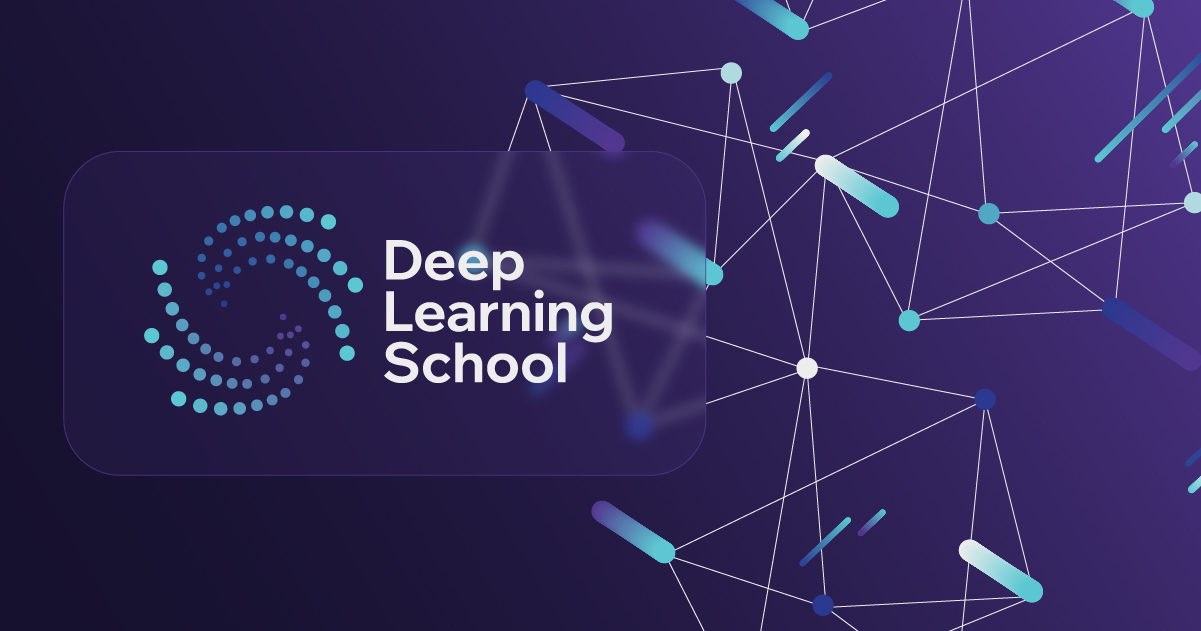

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Библиотека sklearn и классификация с помощью KNN</b></h1>

## Описание домашнего задания

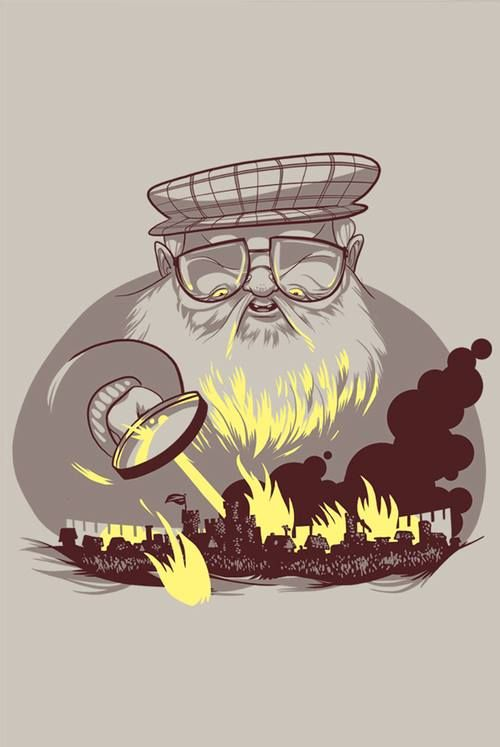

В данном задании вы будете работать с датасетом о персонажах из вселенной Игры Престолов [A Wiki of Ice and Fire](http://awoiaf.westeros.org/). Вам предстоит предсказать, кто из персонажей умрет, а кто останется вживых.



Описание данных:

* **name**: Имя персонажа

* **Title**: Социальный статус или знатность

* **House**: Дом, к которому принадлежит персонаж

* **Culture**: Социальная группа, к которой принадлежит персонаж

* **book1/2/3/4/5**: Появление персонажа в книге

* **Is noble**: Знатность персонажа, основанное на титуле

* **Age**: Отсчет времени: 305 AC

* **male**: Мужчина или женщина

* **dateOfBirth**: дата рождения

* **Spouse**: Имя супруги\а персонажа

* **Father**: Имя отца персонажа

* **Mother**: Имя матери персонажа

* **Heir**: Имя наследника персонажа

* **Is married**: Represents whether the character is married

* **Is spouse alive**: Represents whether character's spouse is alive

* **Is mother alive:** Жива ли мать персонажа

* **Is heir alive:** Жив ли наследник персонажа

* **Is father alive:** Указывает, жив ли отец персонажа

* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан

* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

Оценивание:

Баллы считаются следующим образом:

1) $1.00 \geqslant score \geqslant 0.65$ --- 5 баллов

2) $0.65 > score \geqslant 0.50$ --- 4 балла

3) $0.50 > score \geqslant 0.45$ --- 3 балла

4) $0.45 > score \geqslant 0.40$ --- 2 балла

5) $0.40 > score \geqslant 0.35$ --- 1 балл

6) $0.35 > score$ --- 0 баллов

## Часть 1. Анализ и предобработка данных

Здесь вам необходимо сделать все шаги, которые обсуждались в первой части семинара.
* Предобработка данных
  * Обработка пропущенных данных
  * Создание новых признаков
  * Удаление ненужных столбцов
* Анализ данных
  * Анализ целевой переменной
  * Анализ признаков
  * Анализ влияния признаков на целевую переменную
* Подготовка данных для обучения модели

Загружаем датасет

In [1]:
import os
import urllib.request

os.makedirs('data', exist_ok=True)
files = {
    'game_of_thrones_test.csv': '1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3',
    'game_of_thrones_train.csv': '1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v',
    'submission.csv': '1M14conWjAW2QLoyCXbHEAy8bql2f99eF',
}
for name, file_id in files.items():
    path = os.path.join('data', name)
    if not os.path.exists(path):
        url = f'https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t'
        urllib.request.urlretrieve(url, path)
os.listdir('data')

['submission.csv', 'game_of_thrones_train.csv', 'game_of_thrones_test.csv']

**Задание 1.1.** Импортируйте библиотеки pandas, matplotlib, seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

**Задание 1.2.** Загрузите датасет в Pandas DataFrame при помощи функции `read_csv`. Вместо дефолтных наименований строк `0,1,...`, при помощи параметра `index_col`, сделайте значения колонки `S.No` наименованиями строк:

In [3]:
data = pd.read_csv('data/game_of_thrones_train.csv', index_col='S.No')
data.head()

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity,isAlive
S.No,,,,,,,,,,,,,,,,,,,,,
1,Viserys II Targaryen,NaN,1,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,NaN,...,1.0,0.0,0.0,NaN,0,0,NaN,11,0.605351,0
2,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,House Frey,Perra Royce,...,NaN,NaN,NaN,1.0,1,1,97.0,1,0.896321,1
3,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,House Swyft,NaN,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.267559,1
4,Aemma Arryn,Queen,0,NaN,82.0,NaN,NaN,NaN,House Arryn,Viserys I Targaryen,...,NaN,NaN,NaN,0.0,1,1,23.0,0,0.183946,0
5,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,House Santagar,Eldon Estermont,...,NaN,NaN,NaN,1.0,1,1,29.0,0,0.043478,1


Посмотрите, какие типы данных представлены в нашем датасете

In [4]:
print(data.shape)
data.dtypes

(1557, 25)


name                    str
title                   str
male                  int64
culture                 str
dateOfBirth         float64
mother                  str
father                  str
heir                    str
house                   str
spouse                  str
book1                 int64
book2                 int64
book3                 int64
book4                 int64
book5                 int64
isAliveMother       float64
isAliveFather       float64
isAliveHeir         float64
isAliveSpouse       float64
isMarried             int64
isNoble               int64
age                 float64
numDeadRelations      int64
popularity          float64
isAlive               int64
dtype: object

Знакомый нам метод describe() возвращает различную информацию для столбцов с числовыми типами данных, и с типами данных *object*

Давайте посмотрим на вывод для типа данных *object*. Для этого:
- сначала применим метод describe(). Укажем в качестве аргумента тип данных столбцов, статистику по которым мы хотим посмотреть (см. https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- для удобства восприятия транспонируем таблицу

In [5]:
data.describe(include = 'object').T

,count,unique,top,freq
name,1557,1557,Viserys II Targaryen,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


Теперь давайте посмотрим на столбцы с числовыми типами данных. Дополните код ниже. Для удобства восприятия мы транспонировали таблицу и ограничили вывод тремя столбцами - количество строк без NaN, максимальное и минимальное значение (о кастомизации вариантах вывода describe() вы можете почитать в документации по ссылке выше).


In [6]:
data.describe(include = ['number']).T[['count', 'min', 'max']]

,count,min,max
male,1557.0,0.0,1.0
dateOfBirth,279.0,-25.0,299.0
book1,1557.0,0.0,1.0
book2,1557.0,0.0,1.0
book3,1557.0,0.0,1.0
book4,1557.0,0.0,1.0
book5,1557.0,0.0,1.0
isAliveMother,18.0,0.0,1.0
isAliveFather,22.0,0.0,1.0
isAliveHeir,21.0,0.0,1.0


Так мы проверим, есть ли в данных неадекватнные значения.   Большинство числовых столбцов - это числа от 0 до 1. Отрицательные значения `dateOfBirth` не являются ошибкой. Значения age и `numDeadRelations` также выглядят адекватными. Можно переходить к дальнейшим шагам анализа (анонс - а в тестовых данных нас будет ждать сюрприз).

**Задание 1.3.** Предобработка (очистка) данных.

В нашем домашнем задании все пропуски в данных (missing values) уже закодированы как NaN. Проанализируйте, в каких колонках и как часто встречаются NaN значения. Далее вам надо будет принять решение, как их обрабатывать.

In [7]:
nan_stats = pd.DataFrame({
    'n_nan': data.isna().sum(),
    'share_nan': data.isna().mean().round(3),
})
nan_stats[nan_stats['n_nan'] > 0].sort_values('share_nan', ascending=False)

,n_nan,share_nan
mother,1539,0.988
isAliveMother,1539,0.988
heir,1536,0.987
isAliveHeir,1536,0.987
father,1535,0.986
isAliveFather,1535,0.986
spouse,1357,0.872
isAliveSpouse,1357,0.872
dateOfBirth,1278,0.821
age,1278,0.821


В этом задании удалять строки с NaN (dropna) мы не будем по следующим причинам:
- в обучающем датасете много признаков с большим количество пропусков. Если удалять все строки с NaN, то размер выборки сильно уменьшится. Мы потеряем много данных, которые можно было бы использовать для построения более точной модели.
- тестовом датасете также много признаков с NaN (вы можете в этом убедиться, если скачаете датасет и совершите с ним те же действия, что выше проделали с обучаюшим датасетом). Поэтому нам все-равно придется придумать способ кодировать NaN, чтобы модель делала прогнозы для всех персонажей из тестового датасета. Для этого нам потребуется сохранять, а не удалять данные в обучающем датасете.     



Как вы могли заметить, в наших данных очень много пропущенных значений, причём в некоторых случая пропущена **большая** часть значений. Поэтому заполнять по умолчанию медианой/средним/модой в данном случае - не самый лучший способ (однако, это довольно часто используемый метод заполнения, который может пригодиться вам в будущем)

Ниже мы посмотрим, как можно работать с признаками с большим количеством пропущенных значений.

**Задание 1.4.** Числовые признаки

У нас есть **признак popularity**. Постройте гистограмму распределения данного признака с количеством интервалов (bins), равным 50 (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html)

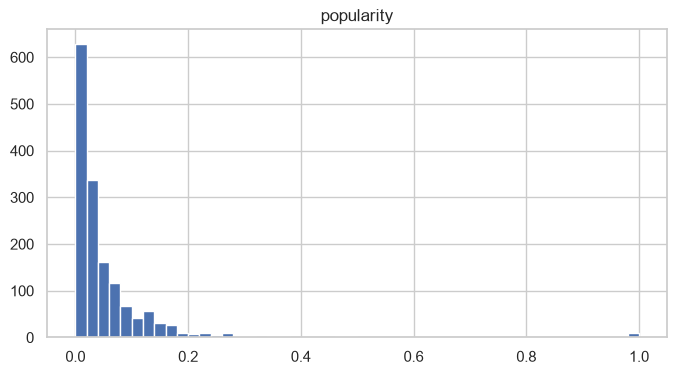

In [8]:
data.hist(column='popularity', bins=50, figsize=(8, 4))
plt.title('popularity')
plt.show()

Распределение сильно несимметрично. Можно преобразовать данный признак, например, по формуле `np.log10(data["popularity"]*M+1)` (добавляем 1 ради логарифма, так как для некоторых персонажей `popularity==0`). В качестве M можно попробовать, например, M=100 или другое число.

При желании для `popularity` вы можете использовать свой способ шкалирования признаков с несимметричным распределением.


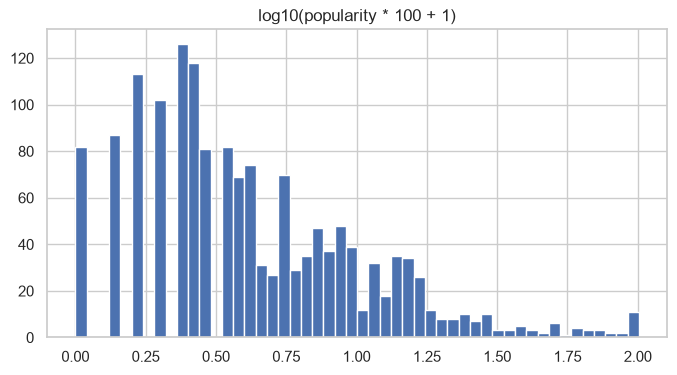

In [9]:
M = 100
data['popularity_log'] = np.log10(data['popularity'] * M + 1)

data.hist(column='popularity_log', bins=50, figsize=(8, 4))
plt.title('log10(popularity * 100 + 1)')
plt.show()

В качестве альтернативного подхода вы можете попробовать дискретизацию признака popularity на основе квантилей (quantile binning), используя функцию qcut() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html). В этом случае вы преобразуете числовой признак popularity в категориальный, для которого в дальнейшем надо будет применить one-hot кодирование.

Теперь давайте обработаем **признак numDeadRelations**.
Посмотрите на частотное распределение этого признака. Лишь для малого числа персонажей `numDeadRelations>0`.

Создайте признак `boolDeadRelations`. Давайте упростим признак `numDeadRelations`, и просто поделим людей на тех, у кого были хоть какие то отношения с мертвыми персонажами, т.е. `numDeadRelations > 0`, и те, у которых не было, т.е. `numDeadRelations = 0`.

In [10]:
print(data['numDeadRelations'].value_counts().sort_index())

data['boolDeadRelations'] = (data['numDeadRelations'] > 0).astype(int)
data['boolDeadRelations'].value_counts()

numDeadRelations
0     1488
1       24
2        4
3        4
4        7
5       10
6        3
7        7
8        2
9        1
10       4
11       1
12       1
15       1
Name: count, dtype: int64


boolDeadRelations
0    1488
1      69
Name: count, dtype: int64

Наконец, давайте посмотрим на **признак age**. В нем очень много пропущенных значений. Для того, чтобы использовать в модели информацию о возрасте персонажа, мы создадим два новых признака: `age_value` и `age_no_data`

- Там где возраст указан, age_value принимает значение `age`, а `age_no_data` - значение 0.
- Там где возраст не указан, `age_value` принимает значение 0, а `age_no_data` - значение 1.  

Фактически, в переменной `age` мы заменяем NaN на 0, но одновременно добавляем в модель еще один бинарный признак `age_no_data`, несущий информацию о том, у каких персонажей не был указан возраст:        

In [11]:
data['age_value'] = data['age'].fillna(0)
data['age_no_data'] = [1 if np.isnan(x) else 0 for x in data['age']]
data[['age', 'age_value', 'age_no_data']].head()

,age,age_value,age_no_data
S.No,,,
1,NaN,0.0,1
2,97.0,97.0,0
3,NaN,0.0,1
4,23.0,23.0,0
5,29.0,29.0,0


Этот способ чем-то похож на работу с категориальной переменными с пропущенными значениями, когда мы добавляем еще одну категорию no_data и заменяем NaN на значение этой категории.

Если вы заходите похожим образом образом обработать признак `dateOfBirth`, **обратите внимание**, что у одних и тех же персонажей не указан и возраст, и год рождения.
То есть созданные признаки `age_no_data` и `dateOfBirth_no_data` будут полностью совпадать, и в модель надо будет включать только один из признаков: или `age_no_data`, или `dateOfBirth_no_data`.

In [12]:
# Проверяем: у персонажей возраст и дата рождения пропущены одновременно
(data['age'].isna() == data['dateOfBirth'].isna()).all()

np.True_

**Задание 1.5.** Категориальные признаки с большим количеством категорий

**Признак culture** содержит информацию о принадлежности к одному из народов во вселенной Игры Престолов.

Давайте посмотрим, какие значения принимает данный признак. По умолчанию метод `value_counts()` игнорирует пропуски в данных, поэтому используем этот метод с параметром **dropna** со значением **False** (см. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html)

In [13]:
data['culture'].value_counts(dropna=False)

culture
NaN                        1069
Northmen                     94
Ironborn                     91
Free Folk                    45
Braavosi                     39
Valyrian                     28
Dornish                      17
Dothraki                     17
Ghiscari                     17
Reach                        13
Vale mountain clans          12
Rivermen                     10
Valemen                      10
northmen                      9
Westerman                     8
Free folk                     7
Tyroshi                       6
Qartheen                      5
Summer Isles                  4
Astapori                      4
Stormlands                    4
Ironmen                       3
Westeros                      3
Westermen                     3
Dornishmen                    3
Northern mountain clans       3
Lysene                        2
westermen                     2
First Men                     2
Meereenese                    2
Myrish                        2


Из полученного частотного распределения видно, что для большого числа персонажей значения данного признака не указаны. Также есть много редких значений признака, которые в выборке повторяются один или несколько раз. Причина отчасти в том, что один и тот же народ упоминается в нашем датасете под разными названиями.

Данную проблему мы попытаемся решить, сгруппировав народы в более крупные категории. Так мы одновременно решим проблему того, что один и тот же народ назван в выборке разными способами.

Предоженный вариант группировки имеет определенную логику. Выделяются следующие группы:
- старые нации, которые уже не сущевали как отдельные народы на момент повествования основной линии повествования романов, но отдельные потомки могли еще быть живы
- народы, проживающие в королевствах континента Весторос (для каждого королевства - своя группа)
- народы континента Эссос
- прочие народы

In [14]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

**Обратите внимание, что некоторые варианты названий народов встречаются только в тестовых данных, и не встречаются в обучающих данных.** Такая ситуация нередко случается на практике. Поэтому, после обработки обучающих данных и обучения модели важно задать для модели правило, как она должна обрабатывать "незнакомые" категории в категориальных признаках. Например, можно относить объекты с "незнакомой" категорией к некоторой существующей категории или указать формулу расчета для "незнакомой" категории.     

Предложенный вам словарь `cultures_grouped` составлен по всем значениям признака `culture`, встречающимся в тренировочном либо в тестовом датасете. Здесь важно, что все укрупненные категории (ключи/keys словаря `cultures_grouped`) представлены в обоих датасетах, а уникальные для тестового датасета названия народов - это отдельные названия народов внутри укрупненных категорий (значения/values словаря). Поэтому, когда вы будете работать с тестовыми - просто применяйте этот словарь без указания правила обработки "незнакомых" категорий.

Давайте приступим к кодировке значений признака culture.
Для этого сначала инвертируем словарь *cultures_grouped*

In [15]:
#Довольно просто инвертировать словарь, где ключу соответствует одно значение
#В нашем случае ключу соответствует список значений.
#Ниже показан пример, как можно инвертировать такой словарь

d = {'A': ['a1', 'a2', 'a3'],
     'B': ['b1', 'b2', 'b3', 'b4']}

d_inverted = {}
for k in d.keys():
  for v in d[k]:
      d_inverted.update({v:k})

d_inverted

{'a1': 'A', 'a2': 'A', 'a3': 'A', 'b1': 'B', 'b2': 'B', 'b3': 'B', 'b4': 'B'}

In [16]:
cultures_grouped_inverted = {}
for k in cultures_grouped.keys():
    for v in cultures_grouped[k]:
        cultures_grouped_inverted.update({v: k})

cultures_grouped_inverted

{'valyrian': 'Old Nations',
 'first men': 'Old Nations',
 'andal': 'Old Nations',
 'andals': 'Old Nations',
 'rhoynar': 'Old Nations',
 'northmen': 'the North',
 'northern mountain clans': 'the North',
 'crannogmen': 'the North',
 'ironborn': 'the Iron Islands',
 'ironmen': 'the Iron Islands',
 'valemen': 'the Mountain and the Vale',
 'vale': 'the Mountain and the Vale',
 'vale mountain clans': 'the Mountain and the Vale',
 'sistermen': 'the Mountain and the Vale',
 'riverlands': 'the Isles and Rivers',
 'rivermen': 'the Isles and Rivers',
 'westerman': 'the Rock',
 'westermen': 'the Rock',
 'westerlands': 'the Rock',
 'stormlander': 'the Stormlands',
 'stormlands': 'the Stormlands',
 'reach': 'the Reach',
 'reachmen': 'the Reach',
 'the reach': 'the Reach',
 'dornish': 'Dorne',
 'dornishmen': 'Dorne',
 'dorne': 'Dorne',
 'astapor': 'Essos Nations',
 'astapori': 'Essos Nations',
 'braavosi': 'Essos Nations',
 'braavos': 'Essos Nations',
 'tyroshi': 'Essos Nations',
 'lysene': 'Essos Na

Теперь создадим новый столбец с укрупненными значениями culture.

Для этого будем использовать метод `map()` с инвертированным словарем в качестве аргумента (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html)

Обратите внимание, что в словаре названия народов указаны в нижнем регистре. А в датасете используется как нижний, так и верхний регистр. Поэтому перед применением метода `map()` переведем значения столбца culture в нижний регистр при помощи метода `str.lower()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.lower.html).

In [17]:
data['culture_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

Осталось заменить все NaN в созданном столбце на категорию `culture_no_data`:

In [18]:
data['culture_grouped'] = data['culture_grouped'].fillna('culture_no_data')
data['culture_grouped'].value_counts()

culture_grouped
culture_no_data              1069
Essos Nations                 109
the North                     108
the Iron Islands               95
Other Nations                  57
Old Nations                    32
the Mountain and the Vale      25
Dorne                          21
the Rock                       14
the Reach                      13
the Isles and Rivers           10
the Stormlands                  4
Name: count, dtype: int64

Распределение сгруппированной переменной выглядит гораздо лучше. Но по прежнему есть несколько слабо представленых групп.

Дальнейшую работу с этим признаком проводите на свое усмотрение для повышения качества прогноза модели. Например, можно объединить несколько слабо представленных категорий в одну или применить другой подход.

**Задание 1.6.** Категориальные признаки в линейных моделях

Для включения категориальных признаков в линейную модель их нужно преобразовать в числовые признаки.

Если признак принимает одно из двух возможных значений (например, персонаж "появляется" или "не появляется" в 1-й книге), он напрямую кодируется в бинарный признак ("появляется" -> 1, "не появляется" -> 0). Если признак принимает больше двух значений, его можно преобразовать в несколько бинарных при помощи one-hot преобразования. В некоторых случаях бывает полезно объединить некоторые категории, как мы это поступили с признаком *culture*.

Порядковых признаков у нас в задаче нет, поэтому рассматривать их здесь мы не будем.

Для того, чтобы найти все порядковые признаки, посмотрим на количество уникальных значений, которые встречаются в столбцах. Для столбцов с типом object количество уникальных значений мы выводили  при помощи метода `describe()` в задании 1.2.

Чтобы посмотреть количество уникальных значений для всех столбцов, можно воспользоваться методом nunique() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html)

In [19]:
# Количество уникальнх значений в каждом столбце
data.nunique()

name                 1557
title                 195
male                    2
culture                51
dateOfBirth           105
mother                 16
father                 19
heir                   20
house                 315
spouse                186
book1                   2
book2                   2
book3                   2
book4                   2
book5                   2
isAliveMother           2
isAliveFather           2
isAliveHeir             2
isAliveSpouse           2
isMarried               2
isNoble                 2
age                    72
numDeadRelations       14
popularity            117
isAlive                 2
popularity_log        117
boolDeadRelations       2
age_value              72
age_no_data             2
culture_grouped        12
dtype: int64

In [20]:
data.describe(include = ['number']).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.0,1.000000,2
dateOfBirth,279.0,-25.0,299.000000,105
book1,1557.0,0.0,1.000000,2
book2,1557.0,0.0,1.000000,2
book3,1557.0,0.0,1.000000,2
book4,1557.0,0.0,1.000000,2
book5,1557.0,0.0,1.000000,2
isAliveMother,18.0,0.0,1.000000,2
isAliveFather,22.0,0.0,1.000000,2
isAliveHeir,21.0,0.0,1.000000,2


Посмотрев на количество уникальных значений мы можем выделить категориальные признаки. Например, `popularity` принимает значения от 0 до 1, но это непрерывный числовой признак. Остальные признаки со значениями от 0 до 1 - принимают только два значения, то есть являются бинарными.

Бинарные признаки без NaN полностью готовы для включения в модель. Некоторые бинарные признаки содержат пропуски, поэтому, если вы захотите включить их в модель, их потребуется обработать.

Для бинарных признаков их связь с зависимой переменной можно прикинуть по таблице корреляций. Для категориальных признаков с количеством значений больше двух (или с двумя значениями и NaN) можно сделать one-hot преобразования и посчитать корреряцию зависимой переменной с набором сгенерированных бинарных признаков.
В качестве альтернативного подхода можно использовать сравнение средних значений зависимой переменной для разных категорий исследуемого признака. Чем сильнее различаются средние значения целевой переменной между категориями, тем вероятнее, что данный признак связан с зависимой переменной.

In [21]:
pd.pivot_table(data = data, values = 'isAlive', index = 'isAliveSpouse', aggfunc=['mean', 'count'], dropna=False)

,mean,count
,isAlive,isAlive
isAliveSpouse,,
0.0,0.619048,42
1.0,0.753165,158
NaN,0.786293,1357


In [22]:
# У isAliveMother / isAliveFather / isAliveHeir заполнено около 1% значений, у isAliveSpouse - около 13%.
# Для isAliveSpouse сохраним информацию о пропуске отдельным признаком, а остальные три столбца не будем использовать.
data['isAliveSpouse_no_data'] = data['isAliveSpouse'].isna().astype(int)
data['isAliveSpouse_value'] = data['isAliveSpouse'].fillna(0)
data.groupby('isAliveSpouse_no_data')['isAlive'].mean()

isAliveSpouse_no_data
0    0.725000
1    0.786293
Name: isAlive, dtype: float64

**Задание 1.7.** Проанализируйте признаки.
  * Обработайте категориальные признаки и переведите их в числа. Можете выбрать любой кодировщик. Не забудьте, что потом аналогичным образом вам надо будет преобразовывать тестовый датасет, используя тот же алгоритм кодирования признаков.
  * Проанализируйте количественные признаки. Есть ли корреляция между признаками?

In [23]:
# Признак house: 300+ уникальных значений, большинство встречается 1-2 раза.
# Оставляем дома, которые встречаются в обучающей выборке хотя бы 10 раз, остальные объединяем в категорию 'other',
# пропуски - в отдельную категорию 'house_no_data'.
house_counts = data['house'].value_counts()
TOP_HOUSES = house_counts[house_counts >= 10].index.tolist()
print('Крупные дома:', TOP_HOUSES)

# Признак title: оставляем только факт наличия титула (свыше половины значений - NaN, много редких титулов)
print(data['title'].value_counts().head(10))

BINARY_FEATURES = ['male', 'book1', 'book2', 'book3', 'book4', 'book5', 'isMarried', 'isNoble']


def preprocess(df):
    """Преобразование сырого датафрейма в матрицу признаков. Одинаково применяется к train и test."""
    X = pd.DataFrame(index=df.index)
    for col in BINARY_FEATURES:
        X[col] = df[col]
    X['books_count'] = df[['book1', 'book2', 'book3', 'book4', 'book5']].sum(axis=1)

    X['popularity_log'] = np.log10(df['popularity'] * 100 + 1)
    X['boolDeadRelations'] = (df['numDeadRelations'] > 0).astype(int)

    X['age_value'] = df['age'].fillna(0)
    X['age_no_data'] = df['age'].isna().astype(int)

    X['isAliveSpouse_value'] = df['isAliveSpouse'].fillna(0)
    X['isAliveSpouse_no_data'] = df['isAliveSpouse'].isna().astype(int)

    X['has_title'] = df['title'].notna().astype(int)
    X['has_house'] = df['house'].notna().astype(int)

    culture = df['culture'].str.lower().map(cultures_grouped_inverted).fillna('culture_no_data')
    X = X.join(pd.get_dummies(culture, prefix='culture').astype(int))

    house = df['house'].where(df['house'].isin(TOP_HOUSES), 'other')
    house = house.where(df['house'].notna(), 'house_no_data')
    X = X.join(pd.get_dummies(house, prefix='house').astype(int))
    return X


features = preprocess(data)
print(features.shape)
features.head()

Крупные дома: ['House Frey', "Night's Watch", 'House Stark', 'House Targaryen', 'House Lannister', 'House Tyrell', 'House Greyjoy', 'House Osgrey', 'Faith of the Seven', 'House Botley', 'House Hightower', 'House Arryn', 'House Martell', 'House Crakehall', 'House Florent']
title
Ser                  306
Maester               29
Archmaester           21
Lord                  19
Septon                16
Winterfell            15
Lady                  10
Princess               9
Septa                  9
King in the North      9
Name: count, dtype: int64
(1557, 46)


,male,book1,book2,book3,book4,book5,isMarried,isNoble,books_count,popularity_log,...,house_House Hightower,house_House Lannister,house_House Martell,house_House Osgrey,house_House Stark,house_House Targaryen,house_House Tyrell,house_Night's Watch,house_house_no_data,house_other
S.No,,,,,,,,,,,,,,,,,,,,,
1,1,0,0,0,0,0,0,0,0,1.789123,...,0,0,0,0,0,0,0,0,1,0
2,1,1,1,1,1,1,1,1,5,1.957282,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,1,0,0,1,1,1.443355,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,1,1,0,1.287682,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,1,0,1,1,1,0.728177,...,0,0,0,0,0,0,0,0,0,1


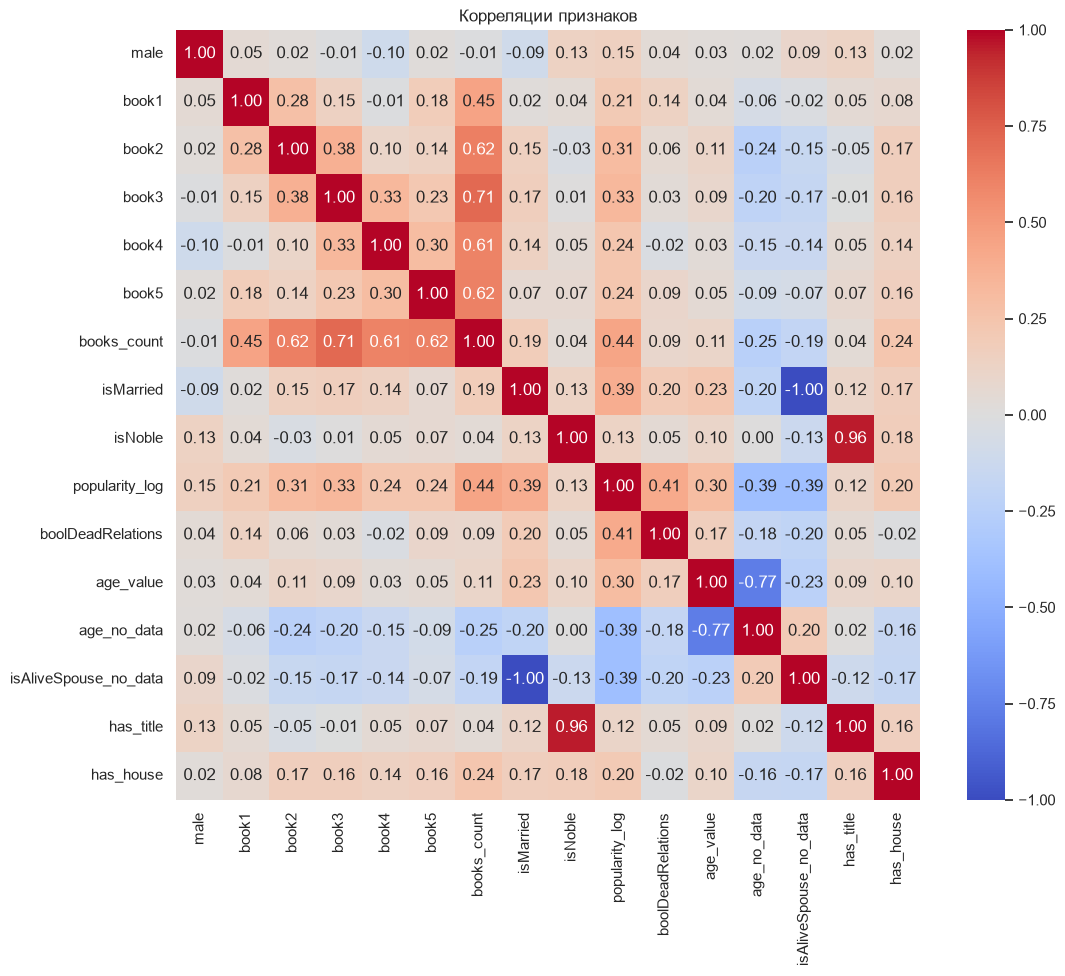

In [24]:
# Корреляции между количественными и бинарными признаками
num_cols = ['male', 'book1', 'book2', 'book3', 'book4', 'book5', 'books_count', 'isMarried', 'isNoble',
            'popularity_log', 'boolDeadRelations', 'age_value', 'age_no_data', 'isAliveSpouse_no_data',
            'has_title', 'has_house']
plt.figure(figsize=(12, 10))
sns.heatmap(features[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляции признаков')
plt.show()

Выводы по корреляциям:
* `has_title` и `isNoble` практически совпадают (знатность определяется по титулу);
* `books_count` сильно коррелирует с появлением в отдельных книгах, а `popularity_log` - с `boolDeadRelations` (у популярных персонажей больше связей);
* `age_no_data` и `isAliveSpouse_no_data` отрицательно связаны с `popularity_log`: о второстепенных персонажах известно меньше.

Сильная мультиколлинеарность мешает интерпретации коэффициентов логистической регрессии, но на деревья почти не влияет.

**Задание 1.8.** Проанализируйте влияние признаков на целевую переменную.

Доля живых персонажей: 0.778


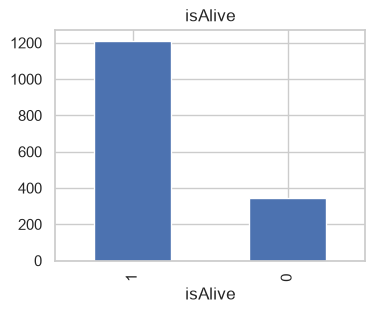

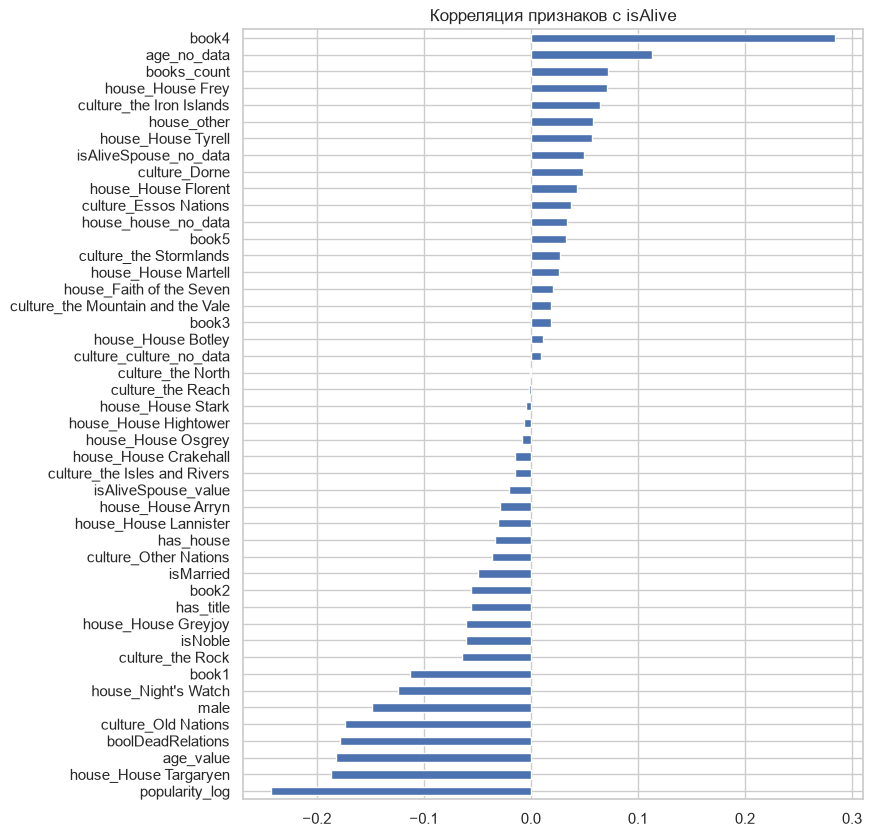

In [25]:
y_full = data['isAlive']
print('Доля живых персонажей:', round(y_full.mean(), 3))
y_full.value_counts().plot(kind='bar', title='isAlive', figsize=(4, 3))
plt.show()

corr_with_target = features.corrwith(y_full).sort_values()
plt.figure(figsize=(8, 10))
corr_with_target.plot(kind='barh')
plt.title('Корреляция признаков с isAlive')
plt.show()

In [26]:
for col in ['male', 'isNoble', 'book1', 'book4', 'book5', 'boolDeadRelations', 'age_no_data']:
    print(data.groupby(col)['isAlive'].agg(['mean', 'count']).round(3), end='\n\n')

print(data.groupby('culture_grouped')['isAlive'].agg(['mean', 'count']).sort_values('mean').round(3))

       mean  count
male              
0     0.852    637
1     0.727    920

          mean  count
isNoble              
0        0.801    873
1        0.750    684

        mean  count
book1              
0      0.797   1341
1      0.662    216

        mean  count
book4              
0      0.645    681
1      0.882    876

        mean  count
book5              
0      0.769   1043
1      0.798    514

                    mean  count
boolDeadRelations              
0                  0.794   1488
1                  0.435     69

              mean  count
age_no_data              
0            0.677    279
1            0.800   1278

                            mean  count
culture_grouped                        
Old Nations                0.281     32
the Rock                   0.500     14
the Isles and Rivers       0.700     10
Other Nations              0.702     57
the Reach                  0.769     13
the North                  0.778    108
culture_no_data            0.781   10

Выводы:
* классы несбалансированы: живых ~78%, поэтому константный прогноз "жив" уже дает accuracy ~0.78 - это бейзлайн;
* сильнее всего с выживанием связано появление в 4-й и 5-й книгах (персонаж жив к концу повествования) и `books_count`;
* персонажи только из 1-й книги, а также с умершими родственниками (`boolDeadRelations`) и высокой популярностью погибают чаще;
* женщины выживают чаще мужчин;
* есть разница между культурами и домами (например, у Old Nations и у некоторых крупных домов доля выживших ниже).

**Задание 1.9.** Создайте переменные `X`, которая будет хранить только значения признаков, которые вы отобрали для включения в модель, и `y`, которая будет хранить только значения целевой переменной.

In [27]:
X = preprocess(data)
y = data['isAlive']
X.shape, y.shape

((1557, 46), (1557,))

**Задание 1.10.** Разделите датасет обучащую и валидационные части (train и val) при помощи функции `train_test_split` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
X_train.shape, X_val.shape

((1167, 46), (390, 46))

## Часть 2. Обучение моделей

В данной части домашнего задания, мы хотим научиться обучать модели для задачи классификации на наших данных.

**Задание 2.1.**


Вы можете работать с одной из предложенных моделей из библиотеки `sklearn`
* LogisticRegression
* RandomForestClassifier
* AdaBoostClassifier
* GaussianProcessClassifier
* GaussianNB
* KNeighborsClassifier
* SVC
* DecisionTreeClassifier


Однако в этом домашнем задании мы предлагаем выбрать и поработать с моделью `LogisticRegression`.

In [30]:
from sklearn.linear_model import LogisticRegression

Импортируйте остальные модели из библиотеки `sklearn`. Чтобы понять как это сделать, воспользуйтесь официальный документацией `sklearn` $→$ [тык](https://scikit-learn.org/dev/user_guide.html). По ключевому названию модели, вы сможете найти необходимую информацию о том, как можно импортировать модель из библиотеки.

In [31]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

**Задание 2.2.** Обучите модель и сделайте предсказание на тестовой выборке

В качестве примера, обучим модель `LogisticRegression` и сделаем на ней предсказания на тестовой выборке.

In [32]:
# Шаг 1. создание модели
# Признаки имеют разный масштаб (age_value до 100, остальные 0-1), поэтому для линейной модели добавляем шкалирование
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))

# Шаг 2. обучение модели
model.fit(X_train, y_train)

# Шаг 3. Предсказание на тестовых данных
y_pred = model.predict(X_val)
y_pred[:20]

array([0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1])

## Часть 3. Оцените качество моделей

Вам необходимо познакомиться с метриками задачи классификации из sklearn. Оцените все модели и выберите лучшую по метрике качества Accuracy.

С метриками классификации вы можете ознакомиться в [Yandex ML Book](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii).

Для простоты в данном домашнем задании мы будем работать с самой базовой метрикой для задачи классификации - accuracy.

**Задание 3.1.** Вам необходимо посчитать метрику для всех моделей и выбрать лучшую модель.

Сначала импортируем необходимую функцию из библиотеки sklearn для подсчета accuracy.

In [33]:
from sklearn.metrics import accuracy_score

В качестве примера, посчитаем метрику accuracy для модели `LogisticRegression`

In [34]:
# Шаг 3. Предсказание на тестовых данных

y_pred = model.predict(X_val)

# Шаг 4. Оценка предсказания по метрике accuracy
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy : %.4f" % accuracy)

Accuracy : 0.8026


Сравним все предложенные модели. Одно разбиение train/val небольшого датасета дает шумную оценку, поэтому дополнительно считаем accuracy на 5-фолдовой стратифицированной кросс-валидации по всему обучающему датасету.

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

models = {
    'LogisticRegression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    'RandomForestClassifier': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'AdaBoostClassifier': AdaBoostClassifier(random_state=RANDOM_STATE),
    'GradientBoostingClassifier': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'GaussianProcessClassifier': make_pipeline(StandardScaler(), GaussianProcessClassifier(random_state=RANDOM_STATE)),
    'GaussianNB': GaussianNB(),
    'KNeighborsClassifier': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'SVC': make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
    'DecisionTreeClassifier': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
for name, clf in models.items():
    clf.fit(X_train, y_train)
    val_acc = accuracy_score(y_val, clf.predict(X_val))
    cv_acc = cross_val_score(clf, X, y, cv=cv, scoring='accuracy').mean()
    results.append({'model': name, 'val_accuracy': val_acc, 'cv_accuracy': cv_acc})

results = pd.DataFrame(results).sort_values('cv_accuracy', ascending=False).reset_index(drop=True)
print('Бейзлайн (всегда "жив"): %.4f' % max(y_val.mean(), 1 - y_val.mean()))
results

Бейзлайн (всегда "жив"): 0.7795


,model,val_accuracy,cv_accuracy
0,RandomForestClassifier,0.841026,0.829821
1,GradientBoostingClassifier,0.817949,0.821467
2,LogisticRegression,0.802564,0.818874
3,SVC,0.797436,0.816961
4,AdaBoostClassifier,0.789744,0.814373
5,GaussianProcessClassifier,0.820513,0.812478
6,KNeighborsClassifier,0.794872,0.812460
7,DecisionTreeClassifier,0.794872,0.800282
8,GaussianNB,0.310256,0.358342


Лучше всего себя показывают ансамбли деревьев, особенно `RandomForestClassifier`. `GaussianNB` работает плохо: предположение о независимых нормально распределенных признаках не выполняется для бинарных признаков.

Подберем гиперпараметры случайного леса и логистической регрессии по кросс-валидации.

In [36]:
from sklearn.model_selection import GridSearchCV

rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {'max_depth': [None, 8, 12, 16], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 0.5]},
    cv=cv, scoring='accuracy')
rf_search.fit(X, y)
print('RandomForest:', rf_search.best_params_, 'CV accuracy = %.4f' % rf_search.best_score_)

lr_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    {'logisticregression__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    cv=cv, scoring='accuracy')
lr_search.fit(X, y)
print('LogisticRegression:', lr_search.best_params_, 'CV accuracy = %.4f' % lr_search.best_score_)

RandomForest: {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 1} CV accuracy = 0.8427


LogisticRegression: {'logisticregression__C': 0.3} CV accuracy = 0.8208


In [37]:
from sklearn.metrics import classification_report, f1_score

best_C = lr_search.best_params_['logisticregression__C']
best_model = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=3000, random_state=RANDOM_STATE))
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_val)
print("Accuracy : %.4f" % accuracy_score(y_val, y_pred))
print("F1 (macro): %.4f" % f1_score(y_val, y_pred, average='macro'))
print(classification_report(y_val, y_pred))

Accuracy : 0.7974
F1 (macro): 0.6502
              precision    recall  f1-score   support

           0       0.57      0.34      0.42        86
           1       0.83      0.93      0.88       304

    accuracy                           0.80       390
   macro avg       0.70      0.63      0.65       390
weighted avg       0.77      0.80      0.78       390



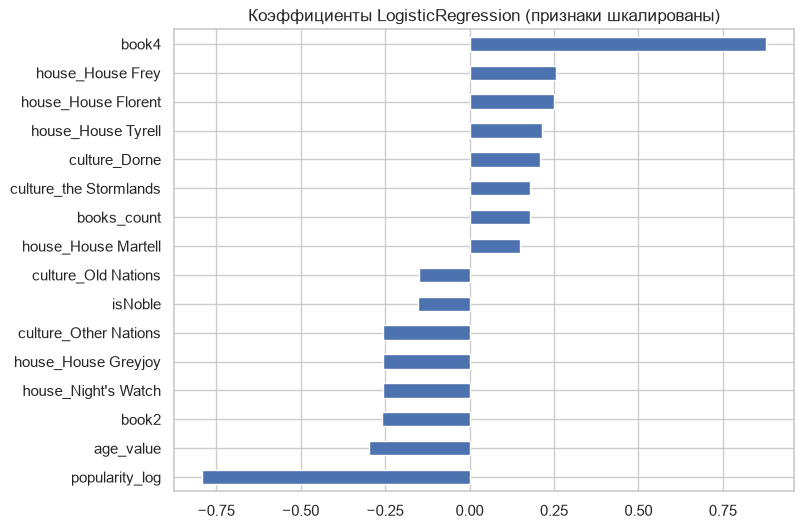

In [38]:
coefs = pd.Series(best_model[-1].coef_[0], index=X.columns).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])
top.plot(kind='barh', figsize=(8, 6), title='Коэффициенты LogisticRegression (признаки шкалированы)')
plt.show()

**Выбранная модель** - `LogisticRegression` с подобранным по кросс-валидации параметром регуляризации `C`: accuracy ~0.82 на кросс-валидации против ~0.78 у константного бейзлайна. (RandomForest дает чуть больше, ~0.84, но по условию задания работаем с логистической регрессией.) Для финального прогноза обучим ее на всем обучающем датасете.

Возможно, вы решите вернуться на несколько шагов и попробовать другие варианты преобразования и подбора признаков в модель. **Выберите** лучшую модель.

### Тестовый датасет

В самом начале нашего домашнего задания мы скачивали тестовый датасет. Загрузите его в Pandas DataFrame при помощи функции read_csv

In [39]:
data_test = pd.read_csv('data/game_of_thrones_test.csv', index_col='S.No')
data_test.shape

(389, 24)

По аналогии с тем, как мы работали с обучающим датасетом, давайте посмотрим в тестовом датасете на статистики признаков с разными типами данных  

In [40]:
data_test.describe(include = 'object').T

,count,unique,top,freq
name,389,389,Melissa Blackwood,1
title,221,109,Ser,78
culture,189,48,Northmen,30
mother,3,3,Dyanna Dayne,1
father,4,4,Maekar I Targaryen,1
heir,2,2,Duncan Targaryen,1
house,343,137,House Targaryen,22
spouse,76,75,Tyrion Lannister,2


In [41]:
data_test.describe(include = ['number']).T[['count', 'min', 'max']]

,count,min,max
male,389.0,0.0,1.0
dateOfBirth,154.0,-28.0,298299.0
book1,389.0,0.0,1.0
book2,389.0,0.0,1.0
book3,389.0,0.0,1.0
book4,389.0,0.0,1.0
book5,389.0,0.0,1.0
isAliveMother,3.0,1.0,1.0
isAliveFather,4.0,0.0,0.0
isAliveHeir,2.0,0.0,1.0


In [42]:
#Подсказка
data_test.loc[data_test['age']<0] # Находим данные с ошибками в дате рождения и возрасте

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,book5,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity
S.No,,,,,,,,,,,,,,,,,,,,,
1685,Doreah,NaN,0,Lysene,278279.0,NaN,NaN,NaN,House Targaryen,NaN,...,1,NaN,NaN,NaN,NaN,0,0,-277980.0,0,0.110368
1869,Rhaego,NaN,0,NaN,298299.0,NaN,NaN,NaN,House Targaryen,NaN,...,0,NaN,NaN,NaN,NaN,0,0,-298001.0,6,0.167224


In [43]:
#Вы можете аккуратно поправить тестовые данные, воспользовавшись, например следующим кодом:
data_test.loc[1685, 'dateOfBirth'] = 278.
data_test.loc[1685, 'age'] = 0.
data_test.loc[1869, 'dateOfBirth'] = 299.
data_test.loc[1869, 'age'] = 0.
data_test.loc[[1685, 1869], ['dateOfBirth', 'age']]

,dateOfBirth,age
S.No,,
1685,278.0,0.0
1869,299.0,0.0


Преобразуйте признаки в тестовом датасете по тому же пайплайну, как вы преобразовывали обучающие данные. Примените вашу лучшую модель на тестовом датасете для получения прогноза целевой переменной `isAlive`

In [44]:
X_test = preprocess(data_test).reindex(columns=X.columns, fill_value=0)

final_model = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=3000, random_state=RANDOM_STATE))
final_model.fit(X, y)
test_pred = final_model.predict(X_test)
print(X_test.shape, 'доля "живых" в прогнозе: %.3f' % test_pred.mean())

(389, 46) доля "живых" в прогнозе: 0.668


### Файл `submission.csv`

Вам нужно вместо значений в `submission.csv` файле в колонке `isAlive`, подставить свои предсказания и сохранить измененный файл.

In [45]:
# submission.csv уже скачан в ячейке загрузки данных в папку data/

In [46]:
submission = pd.read_csv("data/submission.csv", index_col='S.No')

In [47]:
submission

,isAlive
S.No,
1558,0
1559,0
1560,0
1561,0
1562,0
...,...
1942,0
1943,0
1944,0


In [48]:
assert (submission.index == X_test.index).all()
submission['isAlive'] = test_pred
submission['isAlive'].value_counts()

isAlive
1    260
0    129
Name: count, dtype: int64

Как сохранить измененный Pandas DataFrame в csv файл:

In [49]:
# Сохраняем вместе с индексом S.No, чтобы предсказания можно было сопоставить персонажам
submission.to_csv("new_submission.csv")
pd.read_csv("new_submission.csv").head()

,S.No,isAlive
0,1558,0
1,1559,1
2,1560,1
3,1561,1
4,1562,1
